# Standard Binary

## For a particular Theta 

{'0101': 47, '1010': 428, '0111': 8, '1111': 389, '1101': 897, '1000': 2215, '0000': 919, '0010': 5097}
{'1010': 46, '1111': 1, '0111': 8, '0010': 1972, '0000': 44, '1101': 68, '0101': 4595, '1000': 3266}
{'0111': 3, '1010': 11, '1101': 17, '0000': 14, '0010': 2169, '0101': 4827, '1000': 2959}
{'1101': 4, '1010': 3, '0010': 2266, '0000': 8, '0101': 5040, '1000': 2679}
{'0111': 2, '1101': 4, '1010': 1, '0010': 2331, '0000': 6, '1000': 2689, '0101': 4967}
{'0111': 1, '0010': 2369, '0000': 6, '1101': 4, '1000': 2600, '0101': 5020}


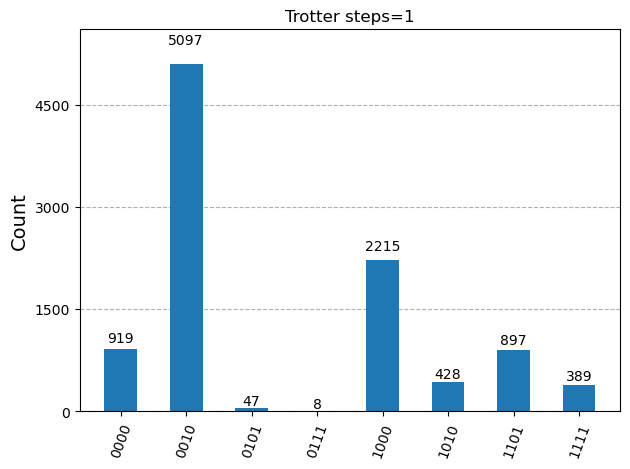

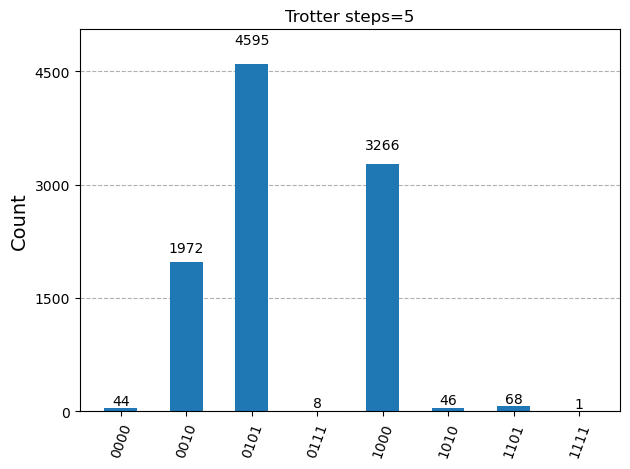

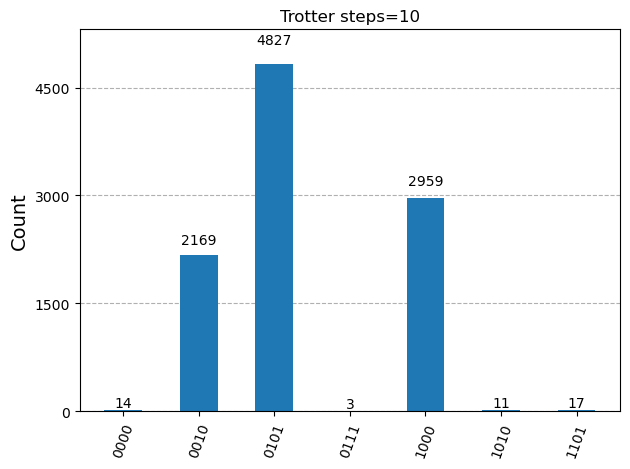

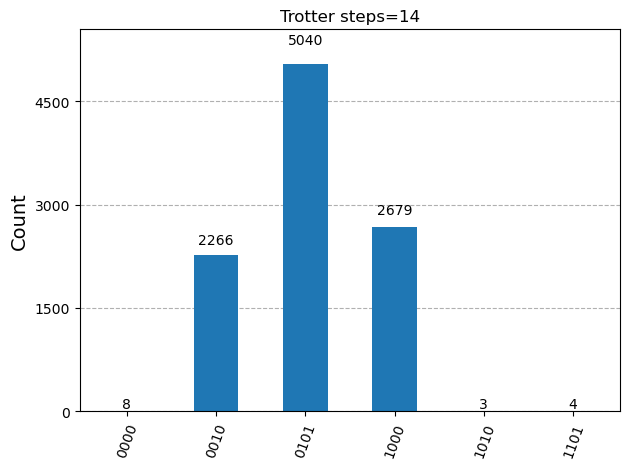

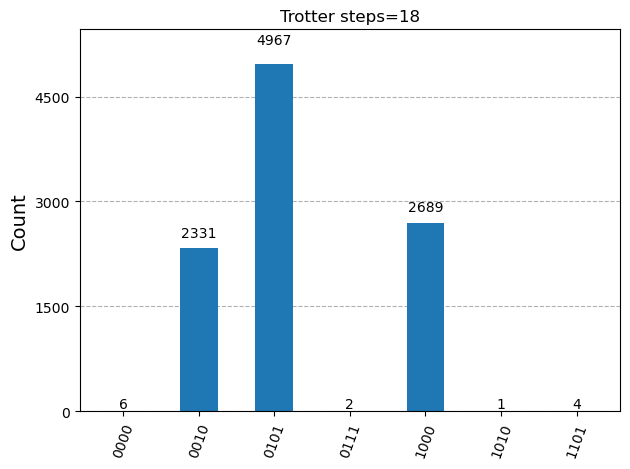

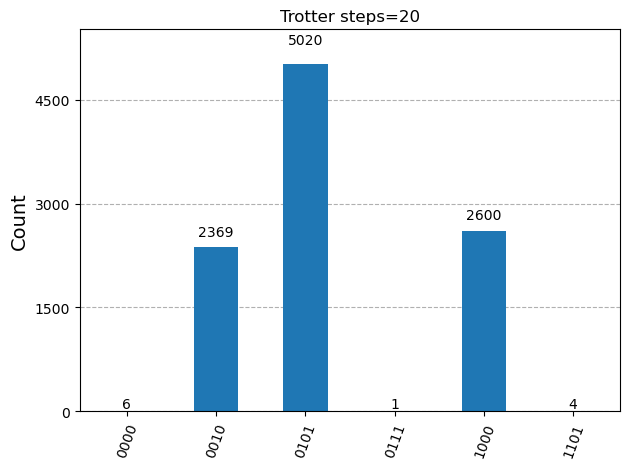

In [2]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Operator, Pauli
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Operator
from qiskit.visualization import plot_histogram
from qiskit.synthesis import LieTrotter
from qiskit_aer import AerSimulator
from IPython.display import display, Math
import matplotlib.pyplot as plt
%matplotlib inline

X=Operator(Pauli("X")).data
Y=Operator(Pauli("Y")).data
Z=Operator(Pauli("Z")).data
I=np.eye(2,dtype=complex)

P_0=0.5*(I+Z)
P_1=0.5*(I-Z)

Q_0=0.5*(X+1j*Y)
Q_1=0.5*(X-1j*Y)

dag= np.kron(P_0,Q_1) + np.sqrt(2)* np.kron(Q_1,Q_0) + np.sqrt(3)* np.kron(P_1,Q_1)
nor= np.kron(P_0,Q_0) + np.sqrt(2)* np.kron(Q_0,Q_1) + np.sqrt(3)* np.kron(P_1,Q_0)

I4=np.eye(4,dtype=complex)

bdag= np.kron(I4,dag)
b=np.kron(I4,nor)

adag= np.kron(dag,I4)
a=np.kron(nor,I4)

H_BS=np.pi/4*(bdag@a + b@adag)

H_BS_P= SparsePauliOp.from_operator(Operator(H_BS))
H_BS_P=H_BS_P.simplify()
#print(H_BS_P)

H_PS=np.pi/4*(bdag@b)

H_PS_P= SparsePauliOp.from_operator(Operator(H_PS))
H_PS_P=H_PS_P.simplify()
#print(H_PS_P)


def BScircuit(trotter_steps):
    qc=QuantumCircuit(4,4)
    qc.x(0)
    qc.x(2)
    evolution1= PauliEvolutionGate(H_BS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_BS")
    qc.append(evolution1,[0,1,2,3])
    evolution2= PauliEvolutionGate(H_PS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_PS")
    qc.append(evolution2,[0,1,2,3])
    evolution3= PauliEvolutionGate(H_BS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_BS")
    qc.append(evolution3,[0,1,2,3])
    qc.measure(range(4),range(4))
    return qc
    

trotter_list=[1,5,10,14,18,20]
backend=AerSimulator()


for n in trotter_list:
    compiled_circuit=transpile(BScircuit(trotter_steps=n), backend)
    job = backend.run(compiled_circuit, shots=10000)
    
    result = job.result()
    counts = result.get_counts()
    print(counts)     
    plot_histogram(counts, title=f"Trotter steps={n}")

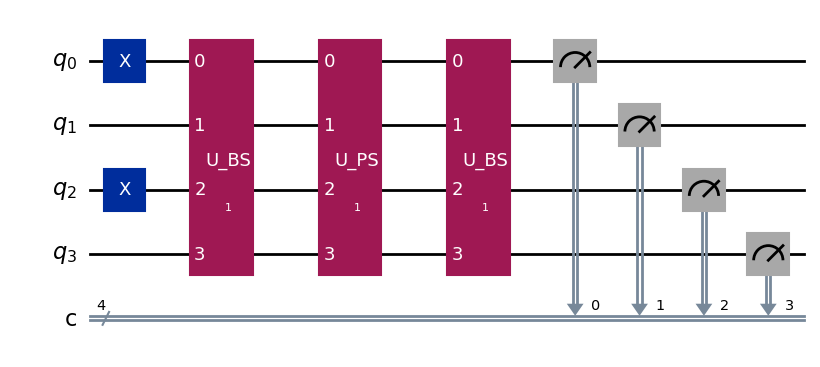

In [2]:
BScircuit(1).draw("mpl")
plt.show()

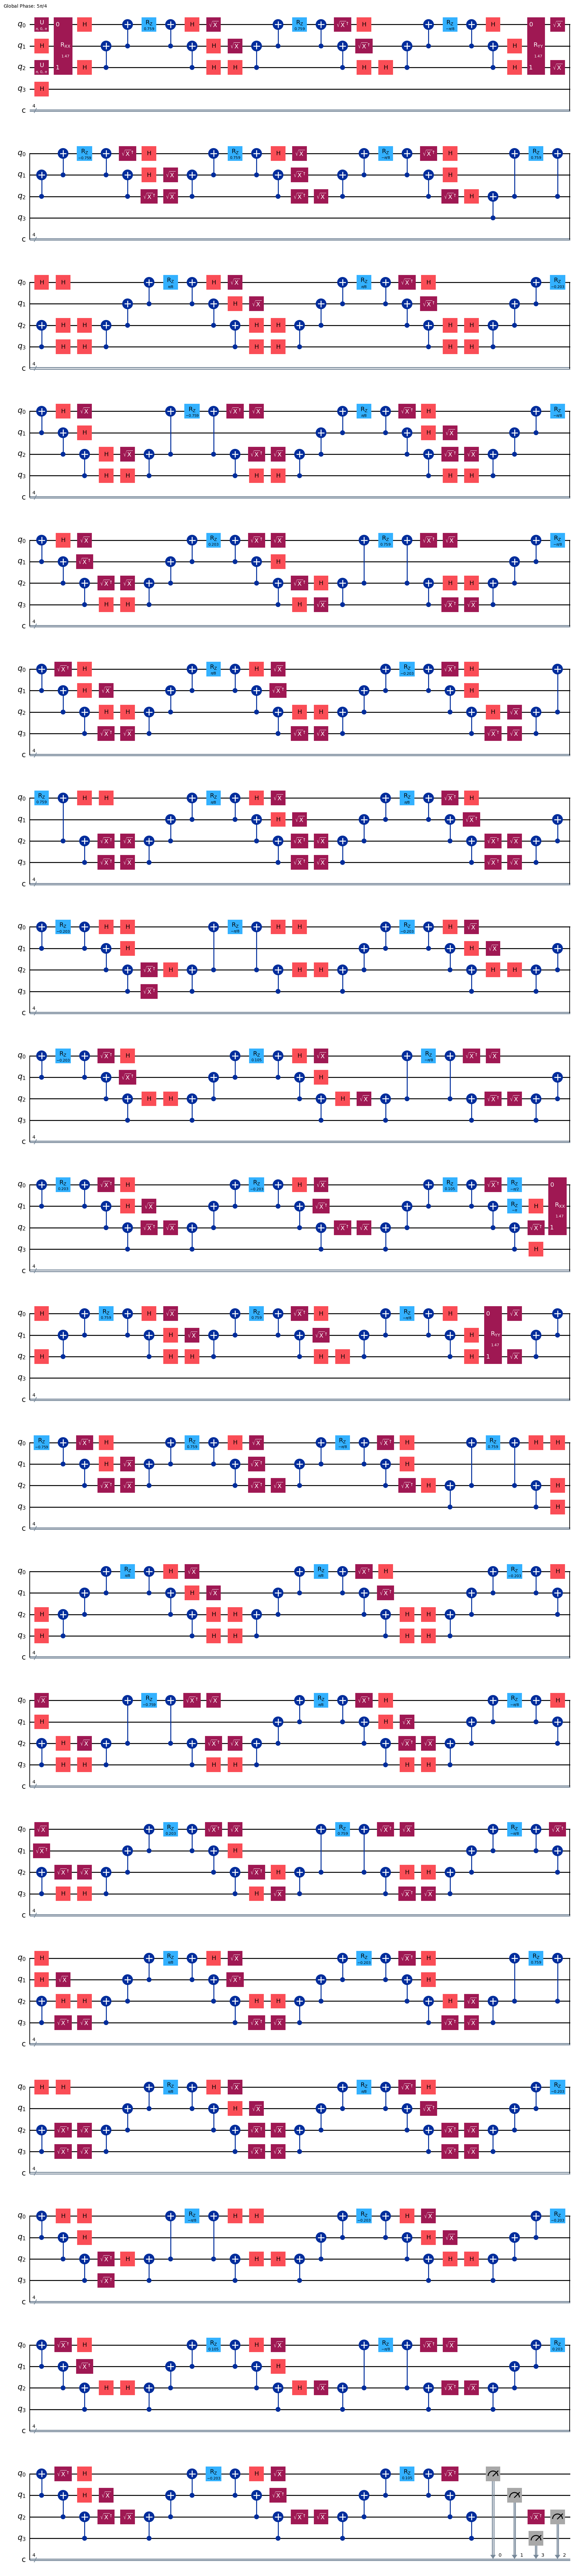

In [3]:
decomposed_circuit=BScircuit(1).decompose()
decomposed_circuit.draw("mpl")
plt.show()

In [4]:
print(decomposed_circuit.depth())

498


In [5]:
print(decomposed_circuit.count_ops())

OrderedDict({'cx': 312, 'h': 184, 'sx': 92, 'sxdg': 92, 'rz': 62, 'measure': 4, 'u': 2, 'rxx': 2, 'ryy': 2})


## Theta Sweep

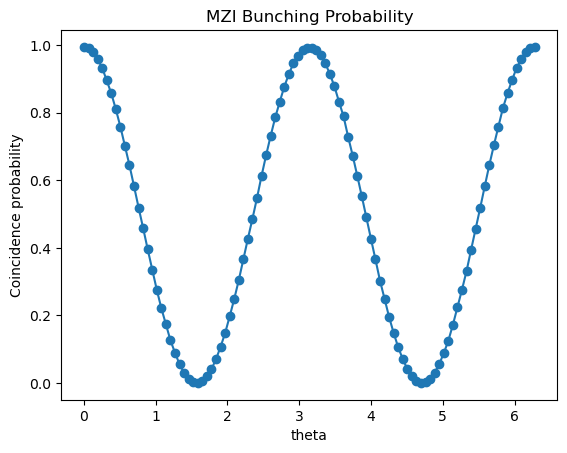

In [3]:
def BScircuit(trotter_steps,phi):
    H_PS=phi*(bdag@b)

    H_PS_P= SparsePauliOp.from_operator(Operator(H_PS))
    H_PS_P=H_PS_P.simplify()
    qc=QuantumCircuit(4,4)
    qc.x(0)
    qc.x(2)
    evolution1= PauliEvolutionGate(H_BS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_BS")
    qc.append(evolution1,[0,1,2,3])
    evolution2= PauliEvolutionGate(H_PS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_PS")
    qc.append(evolution2,[0,1,2,3])
    evolution3= PauliEvolutionGate(H_BS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_BS")
    qc.append(evolution3,[0,1,2,3])
    qc.measure(range(4),range(4))
    return qc



def coincidence_probability(counts, shots):
    total = 0
    for bitstring, c in counts.items():
        bits = bitstring[::-1]   
        m1 = sum(int(b) for b in bits[0:2])
        m2 = sum(int(b) for b in bits[2:4])
        if m1 == 1 and m2 == 1:
            total += c
    return total / shots

backend=AerSimulator()
shots=100000
thetas=np.linspace(0,2*np.pi,100)
coincidences=[]

for phi in thetas:
    qc=BScircuit(20,phi)
    compiled=transpile(qc,backend)
    job=backend.run(compiled, shots=shots)
    result=job.result()
    counts=result.get_counts()
    coincidences.append(coincidence_probability(counts,shots))

plt.plot(thetas, coincidences, 'o-')
plt.xlabel("theta")
plt.ylabel("Coincidence probability")
plt.title("MZI Bunching Probability")
plt.show()